In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mpmath as mp

# Numerical precision for inverse Laplace transforms
mp.mp.dps = 30

In [23]:
# Initial antibiotic concentration
A0 = 10.0

# Diffusion coefficient
D = 2400

# Antibiotic degradation rate in resistant region
k = 1

# Widths of the two regions
L_S = 100.0
L_R = 100.0

# Interface velocities
# Interface position in laboratory coordinates: x_I(t) = -v*t
velocities = [0.0, 0.1, 0.3]


# Number of spatial points in each region
n_space = 31

# Inverse Laplace method
inversion_method = "dehoog"

In [7]:
def laplace_components(s, v):

    a = v / (2 * D)

    mu_s = mp.sqrt(v**2 + 4 * D * s) / (2 * D)
    mu_r = mp.sqrt(v**2 + 4 * D * (s + k)) / (2 * D)

    # Sensitive region: H_S and its derivative
    hs = mp.exp(a * L_S) * (
        mp.cosh(mu_s * L_S)
        - (a / mu_s) * mp.sinh(mu_s * L_S)
    )

    hs_prime = mp.exp(a * L_S) * (
        (s / (D * mu_s)) * mp.sinh(mu_s * L_S)
    )

    # Resistant region: H_R and its derivative
    hr = mp.exp(-a * L_R) * (
        mp.cosh(mu_r * L_R)
        + (a / mu_r) * mp.sinh(mu_r * L_R)
    )

    hr_prime = mp.exp(-a * L_R) * (
        ((s + k) / (D * mu_r)) * mp.sinh(mu_r * L_R)
    )

    # Logarithmic derivatives
    g_s = hs_prime / hs
    g_r = -hr_prime / hr

    # Interface concentration in Laplace space
    A_I_hat = A0 * (
        g_s / s - g_r / (s + k)
    ) / (g_s - g_r)

    return a, mu_s, mu_r, g_s, g_r, A_I_hat

def A_interface_hat(s, v):

    return laplace_components(s, v)[-1]

def A_sensitive_hat(z, s, v):

    a, mu_s, mu_r, g_s, g_r, A_I_hat = laplace_components(s, v)

    y = z + L_S

    H_y = mp.exp(a * y) * (
        mp.cosh(mu_s * y)
        - (a / mu_s) * mp.sinh(mu_s * y)
    )

    H_L = mp.exp(a * L_S) * (
        mp.cosh(mu_s * L_S)
        - (a / mu_s) * mp.sinh(mu_s * L_S)
    )

    return (
        A0 / s
        + (A_I_hat - A0 / s) * H_y / H_L
    )

def A_resistant_hat(z, s, v):

    a, mu_s, mu_r, g_s, g_r, A_I_hat = laplace_components(s, v)

    y = L_R - z

    H_y = mp.exp(-a * y) * (
        mp.cosh(mu_r * y)
        + (a / mu_r) * mp.sinh(mu_r * y)
    )

    H_L = mp.exp(-a * L_R) * (
        mp.cosh(mu_r * L_R)
        + (a / mu_r) * mp.sinh(mu_r * L_R)
    )

    return (
        A0 / (s + k)
        + (A_I_hat - A0 / (s + k)) * H_y / H_L
    )

def inverse_laplace(F, t):

    if t <= 0:
        raise ValueError("Time must be greater than zero.")

    result = mp.invertlaplace(
        F,
        t,
        method=inversion_method
    )

    return float(mp.re(result))

In [8]:
def A_sensitive(z, t, v):

    return inverse_laplace(
        lambda s: A_sensitive_hat(z, s, v),
        t
    )


def A_resistant(z, t, v):

    return inverse_laplace(
        lambda s: A_resistant_hat(z, s, v),
        t
    )


def A_interface(t, v):

    return inverse_laplace(
        lambda s: A_interface_hat(s, v),
        t
    )

In [9]:
def concentration_profile(t, v, n=n_space):

    # Spatial coordinates
    z_s = np.linspace(-L_S, 0, n)
    z_r = np.linspace(0, L_R, n)

    # Sensitive region
    A_s = np.array([
        A_sensitive(z, t, v)
        for z in z_s
    ])

    # Resistant region
    A_r = np.array([
        A_resistant(z, t, v)
        for z in z_r
    ])

    # Combine arrays without duplicating interface
    z = np.concatenate([z_s, z_r[1:]])
    A = np.concatenate([A_s, A_r[1:]])

    return z, A

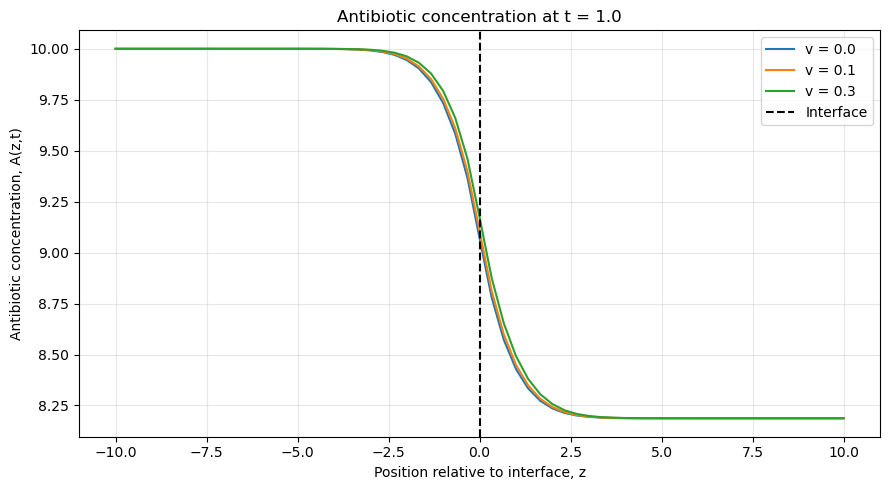

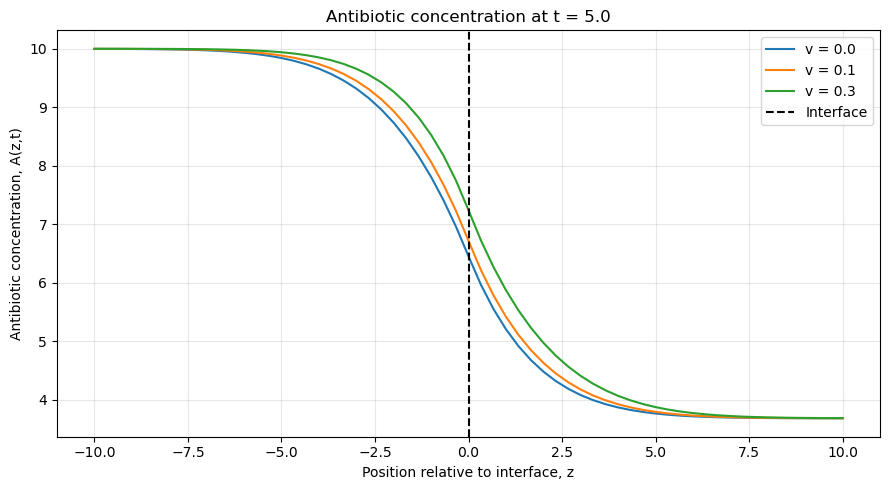

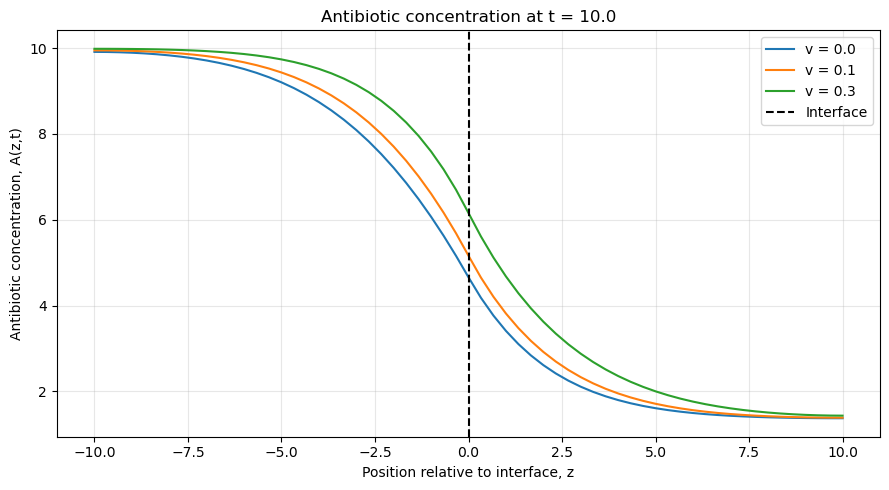

In [ ]:
profiles = {}

# Times at which to calculate concentration profiles
times = [0.2,0.4,0.6,0.8,1.0]

for t in times:

    plt.figure(figsize=(9, 5))

    for v in velocities:

        z, A = concentration_profile(t, v)

        profiles[(v, t)] = (z, A)

        plt.plot(
            z,
            A,
            label=f"v = {v}"
        )

    plt.axvline(
        0,
        color="black",
        linestyle="--",
        label="Interface"
    )

    plt.xlabel("Position relative to interface, z")
    plt.ylabel("Antibiotic concentration, A(z,t)")

    plt.title(f"Antibiotic concentration at t = {t}")

    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

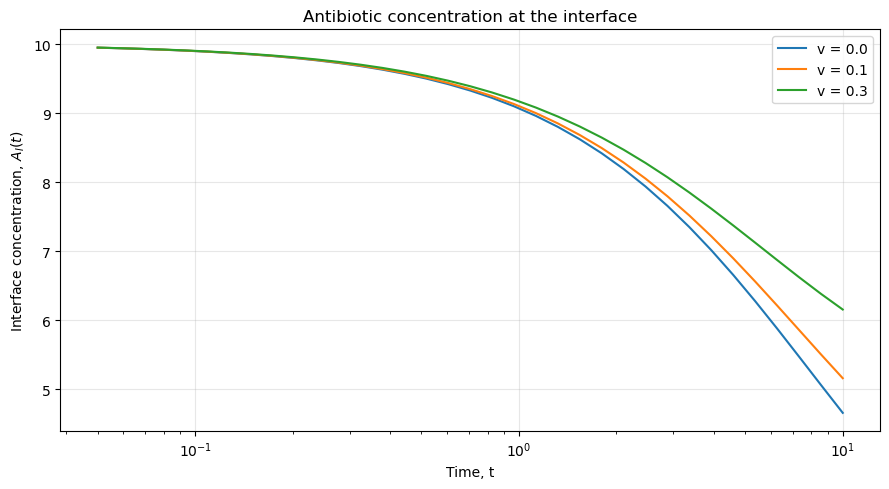

In [11]:
# Time points for interface concentration
t_min = 0.05
t_max = max(times)

n_time = 35

t_grid = np.geomspace(
    t_min,
    t_max,
    n_time
)

interface_results = {}

plt.figure(figsize=(9, 5))

for v in velocities:

    A_I_values = np.array([
        A_interface(t, v)
        for t in t_grid
    ])

    interface_results[v] = A_I_values

    plt.plot(
        t_grid,
        A_I_values,
        label=f"v = {v}"
    )

plt.xscale("log")

plt.xlabel("Time, t")
plt.ylabel("Interface concentration, $A_I(t)$")

plt.title("Antibiotic concentration at the interface")

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

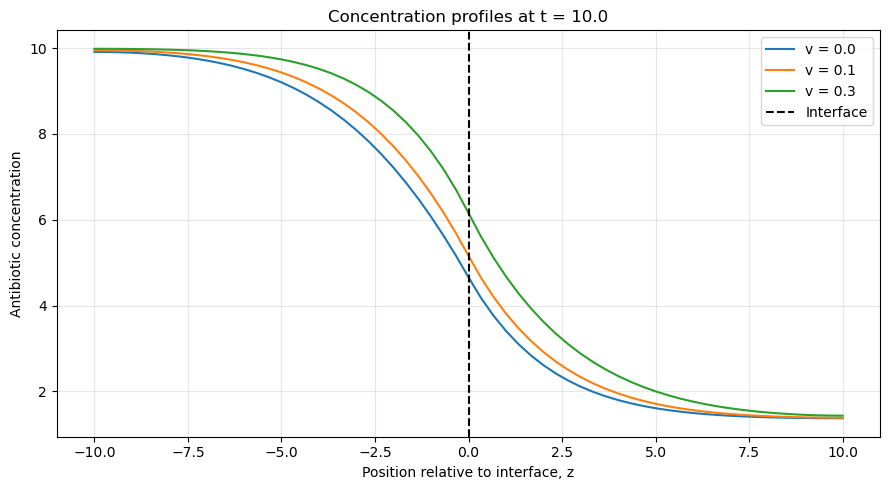

In [12]:
selected_time = times[-1]

plt.figure(figsize=(9, 5))

for v in velocities:

    z, A = profiles[(v, selected_time)]

    plt.plot(
        z,
        A,
        label=f"v = {v}"
    )

plt.axvline(
    0,
    color="black",
    linestyle="--",
    label="Interface"
)

plt.xlabel("Position relative to interface, z")
plt.ylabel("Antibiotic concentration")

plt.title(
    f"Concentration profiles at t = {selected_time}"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
for v in velocities:

    z, A = concentration_profile(times[-1], v)

    # Numerical gradients at outer boundaries
    gradient_left = (A[1] - A[0]) / (z[1] - z[0])
    gradient_right = (A[-1] - A[-2]) / (z[-1] - z[-2])

    # Interface concentration from each side
    A_I_s = A_sensitive(0, times[-1], v)
    A_I_r = A_resistant(0, times[-1], v)

    print(f"\nVelocity v = {v}")

    print("Left boundary gradient:", gradient_left)
    print("Right boundary gradient:", gradient_right)

    print("Interface, sensitive side:", A_I_s)
    print("Interface, resistant side:", A_I_r)

    print("Interface difference:", abs(A_I_s - A_I_r))


Velocity v = 0.0
Left boundary gradient: -0.006277220160455943
Right boundary gradient: -0.0016676403244240104
Interface, sensitive side: 4.657591565835943
Interface, resistant side: 4.657591565835943
Interface difference: 0.0

Velocity v = 0.1
Left boundary gradient: -0.003824479120062556
Right boundary gradient: -0.0027126712735088218
Interface, sensitive side: 5.159741445227219
Interface, resistant side: 5.159741445227219
Interface difference: 0.0

Velocity v = 0.3
Left boundary gradient: -0.0012617117850339788
Right boundary gradient: -0.006415535560727814
Interface, sensitive side: 6.1551571219276795
Interface, resistant side: 6.1551571219276795
Interface difference: 0.0


In [15]:
def concentration_profile_x(t, v, n=n_space):

    # Coordinates in the moving frame
    z_s = np.linspace(-L_S, 0, n)
    z_r = np.linspace(0, L_R, n)

    # Calculate concentrations
    A_s = np.array([
        A_sensitive(z, t, v)
        for z in z_s
    ])

    A_r = np.array([
        A_resistant(z, t, v)
        for z in z_r
    ])

    # Transform to laboratory coordinates: x = z - v*t
    x_s = z_s - v*t
    x_r = z_r - v*t

    return x_s, A_s, x_r, A_r

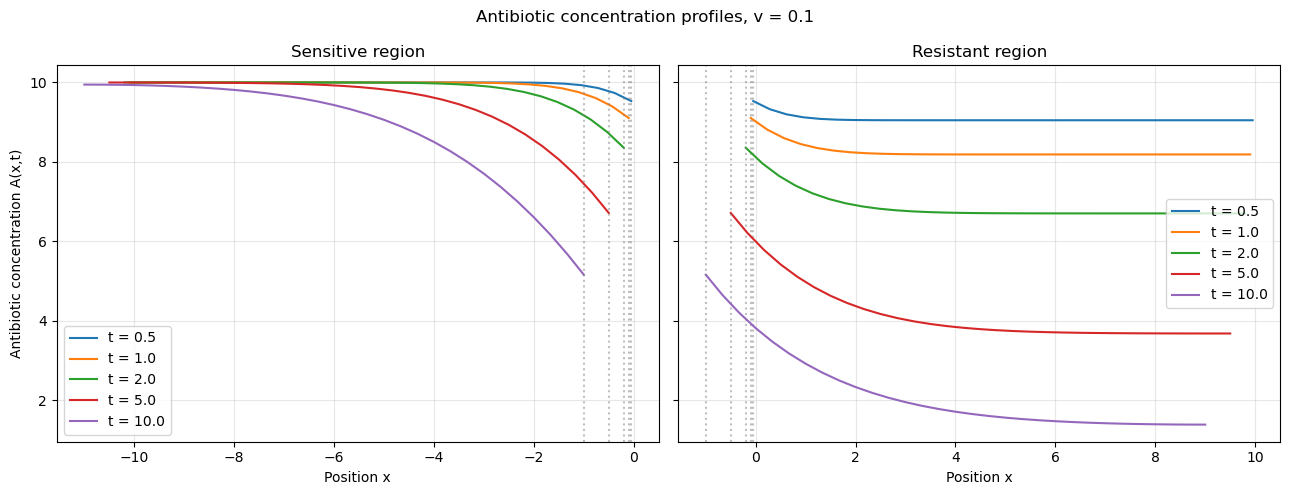

In [16]:
# Choose an interface velocity
selected_v = 0.1

# Choose the time steps
times_to_plot = [0.5, 1.0, 2.0, 5.0, 10.0]

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharey=True
)

for t in times_to_plot:

    x_s, A_s, x_r, A_r = concentration_profile_x(
        t, selected_v
    )

    axes[0].plot(
        x_s, A_s,
        label=f"t = {t}"
    )

    axes[1].plot(
        x_r, A_r,
        label=f"t = {t}"
    )

    # Mark interface position
    x_interface = -selected_v * t

    axes[0].axvline(
        x_interface,
        color="gray",
        linestyle=":",
        alpha=0.5
    )

    axes[1].axvline(
        x_interface,
        color="gray",
        linestyle=":",
        alpha=0.5
    )


axes[0].set_title("Sensitive region")
axes[1].set_title("Resistant region")

for ax in axes:

    ax.set_xlabel("Position x")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Antibiotic concentration A(x,t)")

fig.suptitle(
    f"Antibiotic concentration profiles, v = {selected_v}"
)

plt.tight_layout()
plt.show()

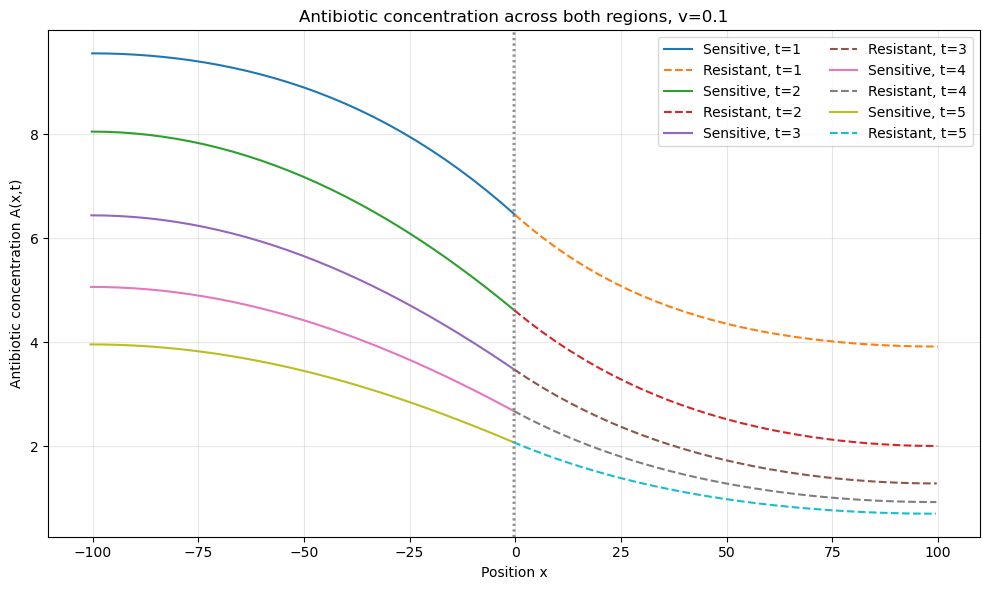

In [25]:
selected_v = 0.1

times_to_plot = [1,2,3,4,5]

plt.figure(figsize=(10, 6))

for t in times_to_plot:

    x_s, A_s, x_r, A_r = concentration_profile_x(
        t, selected_v
    )

    plt.plot(
        x_s, A_s,
        label=f"Sensitive, t={t}"
    )

    plt.plot(
        x_r, A_r,
        linestyle="--",
        label=f"Resistant, t={t}"
    )

    # Interface location
    plt.axvline(
        -selected_v*t,
        color="gray",
        linestyle=":",
        alpha=0.4
    )

plt.xlabel("Position x")
plt.ylabel("Antibiotic concentration A(x,t)")

plt.title(
    f"Antibiotic concentration across both regions, v={selected_v}"
)

plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()